# Chapitre 1 - Cours 2 : décrire la performance, temps de réponse et percentiles

Comment dire qu'un service est « rapide » ? Ce notebook construit le vocabulaire et les
outils de mesure de la performance : temps de réponse, temps de service et latence ;
distributions plutôt que moyennes ; percentiles et leur calcul en continu ; effet des
appels multiples sur la queue de distribution ; objectifs et contrats de niveau de
service. Il couvre la sous-section *Describing Performance* de la section *Scalability* (et son encadré *Percentiles in Practice*).

**Plan.**

1. Débit et temps de réponse.
2. Temps de réponse, temps de service et latence, mesurés côté client et côté serveur.
3. Une distribution, pas un nombre : moyenne, médiane et percentiles.
4. Calculer des percentiles en continu : fenêtres glissantes et histogrammes.
5. L'amplification de la latence de queue.
6. Objectifs et contrats de niveau de service (SLO et SLA).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 1)
rng = np.random.default_rng(0)
Q = [50, 90, 95, 99, 99.9]

## 1. Débit et temps de réponse (section *Describing Performance*)

Deux grandes familles de métriques décrivent la performance d'un logiciel :

- le **débit** (throughput) : nombre de requêtes, ou volume de données, traités par
  seconde. Pour un matériel donné, il existe un débit maximal ;
- le **temps de réponse** : durée entre l'envoi d'une requête par l'utilisateur et la
  réception de la réponse, en secondes ou millisecondes.

Dans l'étude de cas du cours 1, « messages publiés par seconde » et « écritures de
timeline par seconde » sont des débits ; « temps de chargement de la timeline » et
« délai avant qu'un message soit livré aux abonnés » sont des temps de réponse.
Le livre note que les systèmes de traitement par lots (comme Hadoop) se jugent surtout au débit, et les services en ligne au temps de réponse.
Les deux sont liés : le temps de réponse augmente à mesure que le débit approche de la
capacité, à cause des **files d'attente** (cours 3). Le temps de réponse est ce que
ressentent les utilisateurs ; le débit détermine les ressources nécessaires, donc le coût.

> **À retenir.** Débit (« combien par seconde ») et temps de réponse (« combien de temps
> pour une requête ») sont les deux métriques de base ; le premier fixe le coût, le
> second l'expérience utilisateur.

## 2. Temps de réponse, temps de service et latence (section *Describing Performance*)

Les mots « latence » et « temps de réponse » sont souvent employés l'un pour l'autre. Le
livre les distingue :

- le **temps de réponse** est ce que voit le client : il inclut tous les délais, où qu'ils
  se produisent ;
- le **temps de service** est la durée pendant laquelle le serveur traite activement la
  requête ;
- les **délais d'attente en file** (queueing delays) surviennent à plusieurs endroits :
  attendre qu'un cœur se libère, qu'un tampon réseau se vide ;
- la **latence** désigne le temps pendant lequel la requête n'est pas traitée, où elle est
  « latente » ; la **latence réseau** est le temps passé à voyager sur le réseau.

Le diagramme espace-temps ci-dessous (le temps s'écoule de gauche à droite, une ligne
par acteur) décompose une requête qui arrive sur un serveur occupé.

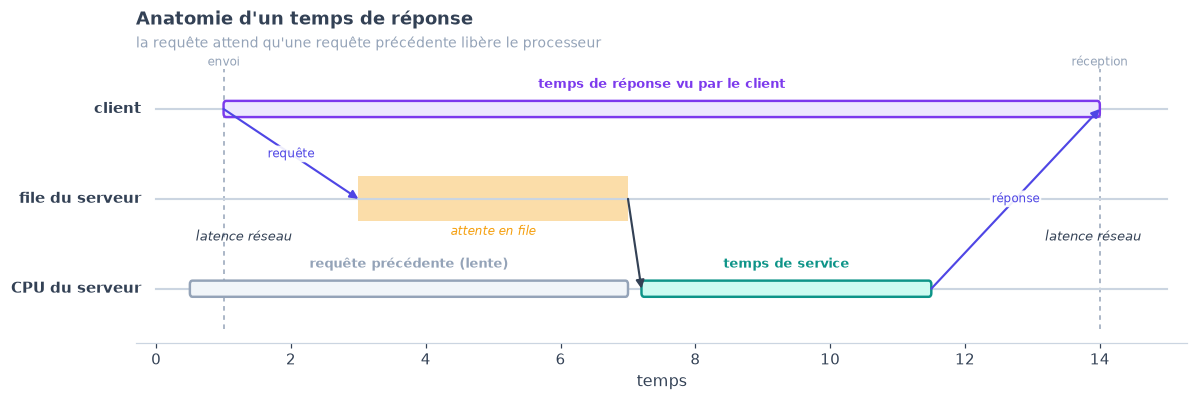

In [2]:
st = SpaceTime(["client", "file du serveur", "CPU du serveur"], t_max=15, width=11,
               title="Anatomie d'un temps de réponse",
               subtitle="la requête attend qu'une requête précédente libère le processeur")
st.op("CPU du serveur", 0.5, 7.0, "requête précédente (lente)", color=GRAY)
st.msg("client", 1.0, "file du serveur", 3.0, "requête", color=INDIGO)
st.span("file du serveur", 3.0, 7.0, "attente en file", color=AMBER, alpha=0.35)
st.msg("file du serveur", 7.0, "CPU du serveur", 7.2, "", color=SLATE)
st.op("CPU du serveur", 7.2, 11.5, "temps de service", color=TEAL)
st.msg("CPU du serveur", 11.5, "client", 14.0, "réponse", color=INDIGO)
st.op("client", 1.0, 14.0, "temps de réponse vu par le client", color=VIOLET)
st.note(1.3, "file du serveur", "latence réseau", dy=-0.42, color=SLATE)
st.note(13.9, "file du serveur", "latence réseau", dy=-0.42, color=SLATE)
st.vline(1.0, "envoi"); st.vline(14.0, "réception")
st.show()

Ce que mesure le serveur (le temps de service, de 7,2 à 11,5) ne représente ici qu'un
tiers de ce que vit le client (de 1 à 14). D'où une règle importante du livre : **mesurer
le temps de réponse côté client**. Vérifions-le par simulation : 50 000 requêtes arrivent
selon un processus de Poisson sur un serveur à un cœur occupé à 50 %, avec un temps de
service log-normal (médiane 8 ms) et un réseau dont les paquets sont parfois perdus puis
retransmis (200 ms de pénalité, la valeur minimale usuelle du délai de retransmission
TCP, pour 0,2 % des messages).

In [3]:
n = 50_000
service = rng.lognormal(np.log(8), 0.6, n)                       # ms
lam = 0.50 / service.mean()                                       # requêtes par ms
send = rq.poisson_arrivals(lam, n, seed=1)
def network(size):
    d = 1.0 + rng.exponential(0.5, size)
    d[rng.random(size) < 0.002] += 200.0                          # retransmission TCP
    return d
aller, retour = network(n), network(n)
start, end = rq.simulate_fifo(send + aller, service)
attente = start - (send + aller)
reponse = aller + attente + service + retour

D = pd.DataFrame({"temps de service (vu par le serveur)": service, "attente en file": attente,
                  "réseau (aller + retour)": aller + retour, "temps de réponse (vu par le client)": reponse})
D.quantile(np.array(Q) / 100).T.set_axis([f"p{q:g}" for q in Q], axis=1).assign(moyenne=D.mean()).round(1)

,p50,p90,p95,p99,p99.9,moyenne
temps de service (vu par le serveur),8.0,17.2,21.4,32.6,51.4,9.6
attente en file,0.1,21.7,30.7,54.7,89.9,7.0
réseau (aller + retour),2.8,4.0,4.4,5.6,203.3,3.8
temps de réponse (vu par le client),15.6,36.9,47.1,78.5,224.5,20.4


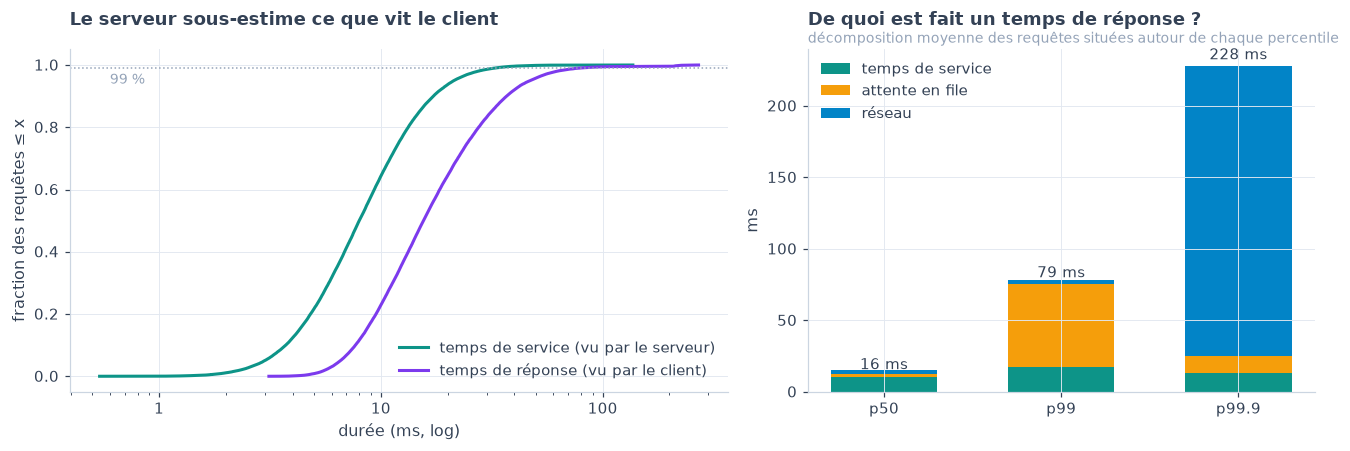

In [4]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
for col, color in zip(["temps de service (vu par le serveur)", "temps de réponse (vu par le client)"], [TEAL, VIOLET]):
    x = np.sort(D[col].values)
    ax.plot(x, np.arange(1, n + 1) / n, color=color, label=col)
ax.set_xscale("log"); rq.plain_log_axis(ax, "x")
ax.set_xlabel("durée (ms, log)"); ax.set_ylabel("fraction des requêtes ≤ x")
ax.axhline(0.99, color=GRAY, ls=":", lw=1); ax.text(0.6, 0.94, "99 %", color=GRAY, fontsize=9)
ax.set_title("Le serveur sous-estime ce que vit le client")
ax.legend(loc="lower right")

parts = ["temps de service (vu par le serveur)", "attente en file", "réseau (aller + retour)"]
qs = [50, 99, 99.9]
bottom = np.zeros(len(qs))
order = np.argsort(reponse)
for col, color in zip(parts, [TEAL, AMBER, SKY]):
    # contribution moyenne de chaque composante chez les requêtes situées autour du percentile
    vals = []
    for q in qs:
        k = int(q / 100 * n)
        idx = order[max(0, k - 50): k + 50]
        vals.append(D[col].values[idx].mean())
    ax2.bar([f"p{q:g}" for q in qs], vals, bottom=bottom, color=color, label=col.split(" (")[0], width=0.6)
    bottom += np.array(vals)
for i, b in enumerate(bottom):
    ax2.text(i, b * 1.02, f"{b:.0f} ms", ha="center", fontsize=9.5)
ax2.set_ylabel("ms"); ax2.set_title("De quoi est fait un temps de réponse ?")
subtitle(ax2, "décomposition moyenne des requêtes situées autour de chaque percentile")
ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()

À la médiane, le temps de réponse est surtout fait de temps de service (le serveur n'est
occupé qu'à moitié, l'attente est souvent nulle). Mais plus on monte dans la queue, plus
il est dominé par **ce que le serveur ne voit pas** : au p99, l'attente en file (des
requêtes rapides bloquées derrière une lente, le **blocage en tête de file**,
head-of-line blocking) ; au p99,9, les retransmissions réseau. Un tableau de bord
alimenté par les seuls temps de service afficherait un p99 plus de deux fois trop
optimiste, et un p99,9 quatre fois trop optimiste.

> **À retenir.** Temps de réponse = latences réseau + attentes en file + temps de
> service. Les attentes et les aléas dominent la queue de la distribution et sont
> invisibles du serveur : on mesure côté client.

## 3. Une distribution, pas un nombre (section *Describing Performance*)

Même en répétant exactement la même requête, le temps de réponse varie : changement de
contexte vers un processus d'arrière-plan, paquet perdu, pause du ramasse-miettes (GC),
défaut de page... Il faut donc le penser comme une **distribution**. Traçons 100 requêtes
consécutives d'un service (générateur `rq.synthetic_response_times` : corps log-normal
plus 1,5 % de requêtes ralenties par un aléa).

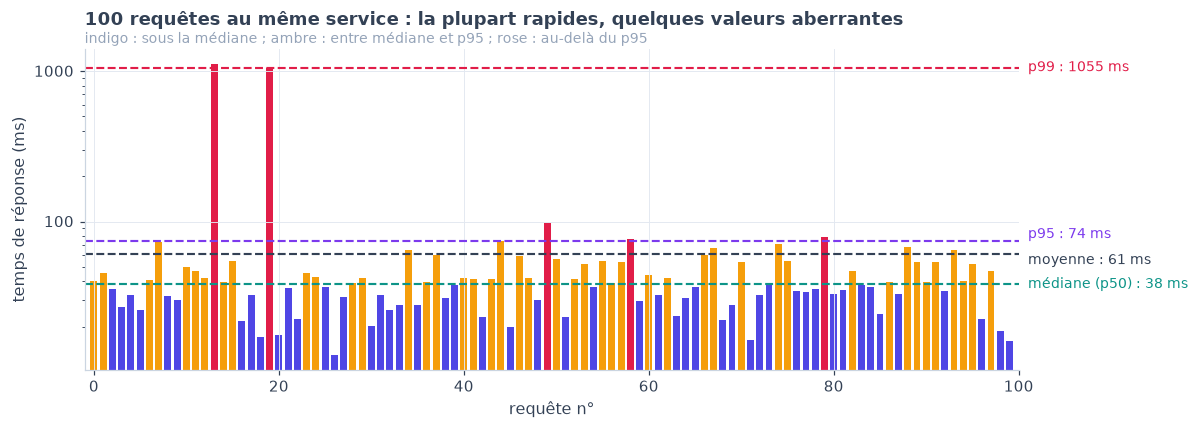

In [5]:
x100 = rq.synthetic_response_times(100, seed=7)
stats = {"moyenne": x100.mean(), "médiane (p50)": rq.percentile(x100, 50), "p95": rq.percentile(x100, 95),
         "p99": rq.percentile(x100, 99)}
fig, ax = plt.subplots(figsize=(11, 4))
cols = np.where(x100 > stats["p95"], ROSE, np.where(x100 > stats["médiane (p50)"], AMBER, INDIGO))
ax.bar(np.arange(100), x100, color=cols, width=0.75)
for (nom, v), c, va in zip(stats.items(), [SLATE, TEAL, VIOLET, ROSE], ["top", "center", "bottom", "center"]):
    ax.axhline(v, color=c, ls="--", lw=1.4)
    ax.text(101, v, f"{nom} : {v:.0f} ms", color=c, va=va, fontsize=9)
ax.set_xlim(-1, 100); ax.set_xlabel("requête n°"); ax.set_ylabel("temps de réponse (ms)")
ax.set_yscale("log"); rq.plain_log_axis(ax, "y")
ax.set_title("100 requêtes au même service : la plupart rapides, quelques valeurs aberrantes")
subtitle(ax, "indigo : sous la médiane ; ambre : entre médiane et p95 ; rose : au-delà du p95")
plt.tight_layout(); plt.show()

**La moyenne** (somme divisée par le nombre de requêtes) est utile pour estimer des
limites de débit, mais elle ne dit pas combien d'utilisateurs ont réellement subi tel
délai : ici, quelques requêtes lentes la tirent nettement au-dessus de la médiane, et
aucune requête ne prend « la moyenne ».

**Les percentiles** se lisent sur la liste triée. La **médiane** (p50) partage les
requêtes en deux moitiés : c'est le temps d'attente *typique*. Les percentiles élevés,
p95, p99, p999 (99,9e), mesurent la gravité des valeurs aberrantes : un p95 de 1,5 s
signifie que 5 requêtes sur 100 prennent 1,5 s ou plus. On les appelle **latences de
queue** (tail latencies).

Sur 100 000 requêtes, la forme de la distribution apparaît nettement : un corps
en cloche (en échelle log) et une **seconde bosse** de requêtes ralenties.

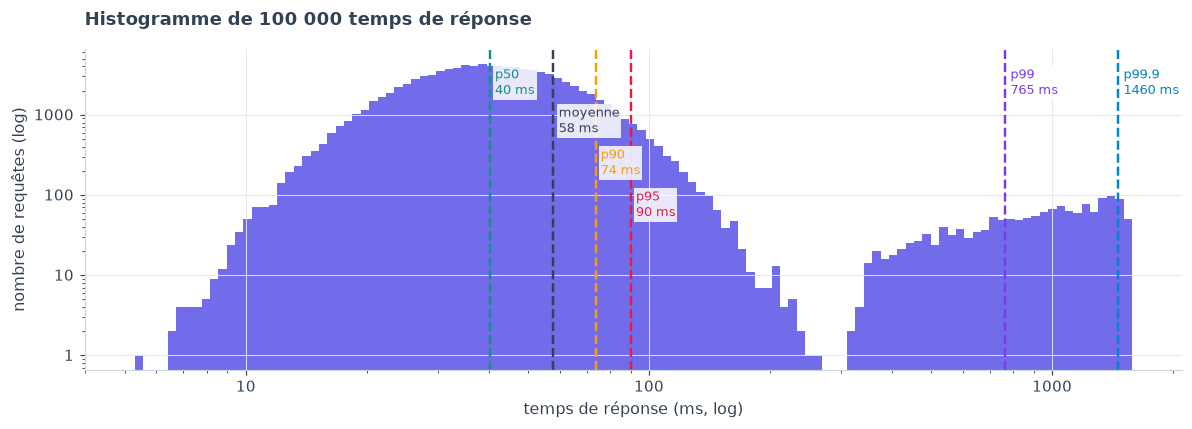

,moyenne,p50,p90,p95,p99,p99.9
valeur (ms),58.0,40.3,73.7,90.1,764.9,1459.6


In [6]:
x = rq.synthetic_response_times(100_000, seed=0)
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 120)
ax.hist(x, bins=bins, color=INDIGO, alpha=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); rq.plain_log_axis(ax)
ymax = ax.get_ylim()[1]
hauteurs = [0.2, 0.6, 0.06, 0.018, 0.6, 0.6]
for (nom, v), c, hy in zip([("moyenne", x.mean())] + [(f"p{q:g}", rq.percentile(x, q)) for q in Q],
                           [SLATE] + COLORS[1:], hauteurs):
    ax.axvline(v, color=c, lw=1.6, ls="--")
    ax.text(v * 1.03, ymax * hy, f"{nom}\n{v:.0f} ms", color=c, fontsize=8.5, va="top",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.set_xlabel("temps de réponse (ms, log)"); ax.set_ylabel("nombre de requêtes (log)")
ax.set_title("Histogramme de 100 000 temps de réponse")
plt.tight_layout(); plt.show()
pd.DataFrame({"valeur (ms)": [x.mean()] + [rq.percentile(x, q) for q in Q]},
             index=["moyenne"] + [f"p{q:g}" for q in Q]).T

Le p99 tombe dans la bosse des requêtes ralenties : il vaut une vingtaine de fois la
médiane. La moyenne, elle, se situe entre la médiane et le p95, sans signification
particulière.

**Pourquoi s'intéresser au p999 ?** Le livre cite Amazon, qui fixe ses exigences internes
au 99,9e percentile alors que cela ne concerne qu'une requête sur 1 000 : les clients
dont les requêtes sont les plus lentes sont souvent ceux qui ont le plus de données
(beaucoup d'achats), donc les plus précieux. Aller plus loin (p9999) a été jugé trop
coûteux pour un bénéfice trop faible : les très hauts percentiles dépendent d'aléas qu'on
ne maîtrise pas.

Il y a une autre raison, plus mathématique : un utilisateur fait **beaucoup de
requêtes**. Une session de chargement de page qui déclenche 30 requêtes en voit au moins
une au-delà du p99 avec une probabilité $1 - 0{,}99^{30} \approx 26\,\%$. Les queues de
distribution concernent donc bien plus d'utilisateurs que leur nom ne le laisse croire.

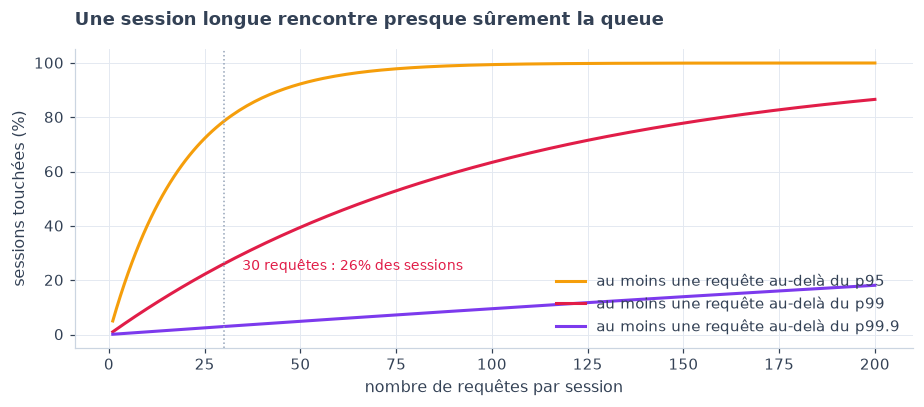

In [7]:
k = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for q, c in [(95, AMBER), (99, ROSE), (99.9, VIOLET)]:
    ax.plot(k, rq.p_any_slow(1 - q / 100, k) * 100, color=c, label=f"au moins une requête au-delà du p{q:g}")
ax.axvline(30, color=GRAY, ls=":", lw=1)
ax.annotate(f"30 requêtes : {rq.p_any_slow(0.01, 30):.0%} des sessions", (30, rq.p_any_slow(0.01, 30) * 100), (12, -4),
            textcoords="offset points", fontsize=9, color=ROSE)
ax.set_xlabel("nombre de requêtes par session"); ax.set_ylabel("sessions touchées (%)")
ax.set_title("Une session longue rencontre presque sûrement la queue")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

> **À retenir.** Le temps de réponse est une distribution. La médiane décrit le cas
> typique, les hauts percentiles (p99, p999) les cas lents ; la moyenne ne décrit
> personne. Comme un utilisateur fait de nombreuses requêtes, la queue le concerne
> presque toujours.

## 4. Calculer des percentiles en continu (encadré *Percentiles in Practice*)

Un tableau de bord affiche typiquement, chaque minute, les percentiles des 10 dernières
minutes (une **fenêtre glissante**). L'implémentation naïve garde tous les temps de
réponse de la fenêtre et les trie à chaque calcul : coûteux en mémoire et en temps
quand le débit est élevé. Il existe des algorithmes qui donnent une bonne approximation
pour un coût minime (décroissance « vers l'avant » ou forward decay, t-digest, HdrHistogram).

**Idée d'HdrHistogram, recodée simplement** (`rq.LogLinearHistogram`). On découpe chaque
puissance de deux $[2^e, 2^{e+1})$ en $2^s$ seaux de même largeur. Une valeur tombe
dans le seau d'indice $e \cdot 2^s + \lfloor (v/2^e - 1)\, 2^s \rfloor$ ; on ne stocke
que des compteurs. En restituant le milieu du seau, l'**erreur relative** est au plus
$2^{-(s+1)}$, quelle que soit la valeur : 1,6 % pour $s = 5$. La mémoire dépend de la
plage dynamique (du plus petit au plus grand temps) et de $s$, **pas du nombre de
requêtes**.

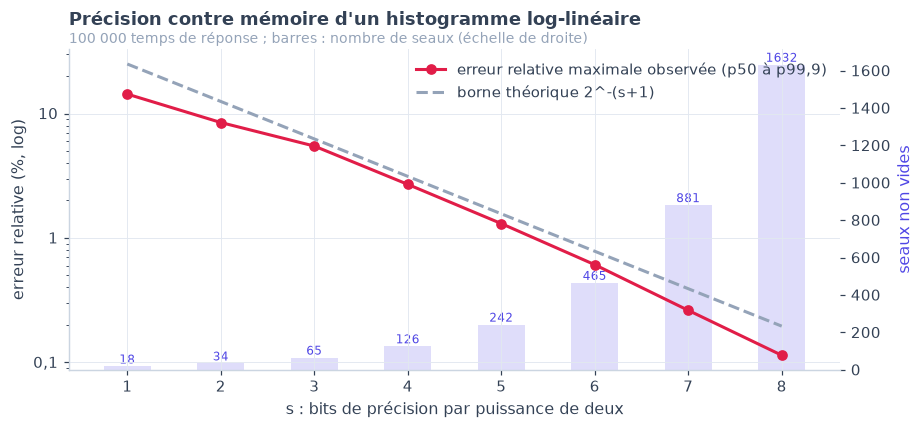

,sub_bits,seaux,erreur_max,borne
0,1,18,14.3,25.0
1,2,34,8.5,12.5
2,3,65,5.5,6.2
3,4,126,2.7,3.1
4,5,242,1.3,1.6
5,6,465,0.6,0.8
6,7,881,0.3,0.4
7,8,1632,0.1,0.2


In [8]:
exact = {q: rq.percentile(x, q) for q in Q}
rows = []
for s in range(1, 9):
    h = rq.LogLinearHistogram(sub_bits=s, unit=1e-3)
    h.record_many(x)
    err = max(abs(h.percentile(q) - exact[q]) / exact[q] for q in Q)
    rows.append(dict(sub_bits=s, seaux=h.n_buckets, erreur_max=err * 100, borne=h.max_relative_error() * 100))
E = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(E.sub_bits, E.erreur_max, "o-", color=ROSE, label="erreur relative maximale observée (p50 à p99,9)")
ax.plot(E.sub_bits, E.borne, "--", color=GRAY, label="borne théorique 2^-(s+1)")
ax.set_yscale("log"); rq.plain_log_axis(ax, "y")
ax.set_xlabel("s : bits de précision par puissance de deux"); ax.set_ylabel("erreur relative (%, log)")
ax2 = ax.twinx()
ax2.bar(E.sub_bits, E.seaux, color=INDIGO, alpha=0.18, width=0.5)
ax2.set_ylabel("seaux non vides", color=INDIGO); ax2.grid(False)
for _, r in E.iterrows():
    ax2.text(r.sub_bits, r.seaux, f"{r.seaux:.0f}", ha="center", va="bottom", fontsize=8, color=INDIGO)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_title("Précision contre mémoire d'un histogramme log-linéaire")
subtitle(ax, "100 000 temps de réponse ; barres : nombre de seaux (échelle de droite)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
E

Avec $s = 5$, quelques centaines de compteurs suffisent pour résumer 100 000 valeurs
avec une erreur d'au plus 1,6 %, et ce nombre ne grandirait pas avec un million de
requêtes. L'erreur observée reste sous la borne théorique.

**Fenêtre glissante.** `rq.RollingPercentiles` garde un histogramme par minute et
fusionne les 10 dernières minutes pour répondre. Simulons une heure de trafic
(100 requêtes par seconde) avec un incident entre les minutes 25 et 32 (5 % de requêtes
ralenties au lieu de 1,5 %), puis comparons au calcul exact par tri.

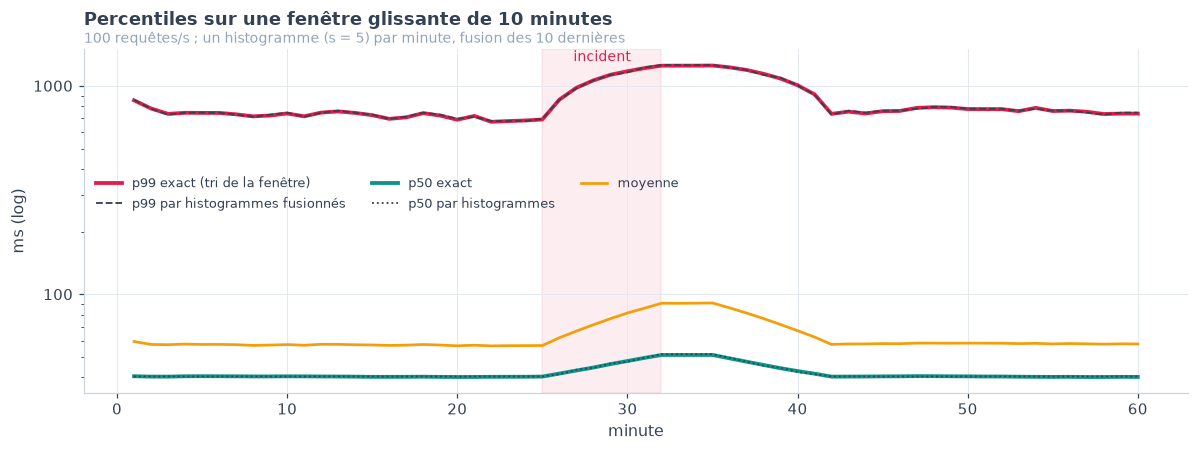

écart relatif maximal p99 histogramme / exact : 1.28%
mémoire : 60 365 valeurs dans la fenêtre contre 1836 compteurs


In [9]:
rate, minutes = 100, 60
t_req = np.sort(rng.uniform(0, minutes * 60, rate * minutes * 60))
incident = (t_req >= 25 * 60) & (t_req < 32 * 60)
v_req = rq.synthetic_response_times(t_req.size, seed=3)
v_req[incident] = rq.synthetic_response_times(incident.sum(), seed=4, p_slow=0.05, median_ms=55)

roll = rq.RollingPercentiles(window=10, slot=60, sub_bits=5)
roll.add_many(t_req, v_req)
res = []
t0 = time.perf_counter(); naive_time = 0.0
for m in range(1, minutes + 1):
    win = (t_req >= (m - 10) * 60) & (t_req < m * 60)
    t1 = time.perf_counter()
    vals = np.sort(v_req[win]); naive_time += time.perf_counter() - t1
    t1 = time.perf_counter()
    approx = {q: roll.percentile(m * 60 - 1e-9, q) for q in (50, 99)}
    res.append(dict(minute=m, p50=rq.percentile(vals, 50), p99=rq.percentile(vals, 99),
                    p50_h=approx[50], p99_h=approx[99], moyenne=vals.mean(), n=vals.size))
R = pd.DataFrame(res)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(25, 32, color=ROSE, alpha=0.08)
ax.text(28.5, R.p99.max() * 1.05, "incident", color=ROSE, ha="center", fontsize=9)
ax.plot(R.minute, R.p99, color=ROSE, lw=2.5, label="p99 exact (tri de la fenêtre)")
ax.plot(R.minute, R.p99_h, color=SLATE, lw=1.2, ls="--", label="p99 par histogrammes fusionnés")
ax.plot(R.minute, R.p50, color=TEAL, lw=2.5, label="p50 exact")
ax.plot(R.minute, R.p50_h, color=SLATE, lw=1.2, ls=":", label="p50 par histogrammes")
ax.plot(R.minute, R.moyenne, color=AMBER, lw=1.8, label="moyenne")
ax.set_yscale("log"); rq.plain_log_axis(ax, "y")
ax.set_xlabel("minute"); ax.set_ylabel("ms (log)")
ax.set_title("Percentiles sur une fenêtre glissante de 10 minutes")
subtitle(ax, f"{rate} requêtes/s ; un histogramme (s = 5) par minute, fusion des 10 dernières")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.58), ncol=3, fontsize=8.5)
plt.tight_layout(); plt.show()
print(f"écart relatif maximal p99 histogramme / exact : {((R.p99_h - R.p99).abs() / R.p99).max():.2%}")
print(f"mémoire : {R.n.max():,} valeurs dans la fenêtre contre "
      f"{sum(h.n_buckets for h in roll.slots.values())} compteurs".replace(",", " "))

Les courbes approchées se superposent aux exactes. Notez la **mémoire** de la fenêtre :
l'incident reste visible dans le p99 pendant 10 minutes après sa fin, le temps qu'il
sorte de la fenêtre. La moyenne réagit aussi, mais elle mélange en un seul nombre
l'augmentation de la médiane et celle de la queue.

**Ne jamais moyenner des percentiles.** Pour réduire la résolution temporelle ou
combiner plusieurs machines, la tentation est de faire la moyenne de leurs p99. C'est
mathématiquement dénué de sens : le bon calcul consiste à **additionner les
histogrammes**. Exemple : quatre serveurs derrière un répartiteur, dont un reçoit peu de
trafic mais souffre de pauses du ramasse-miettes fréquentes.

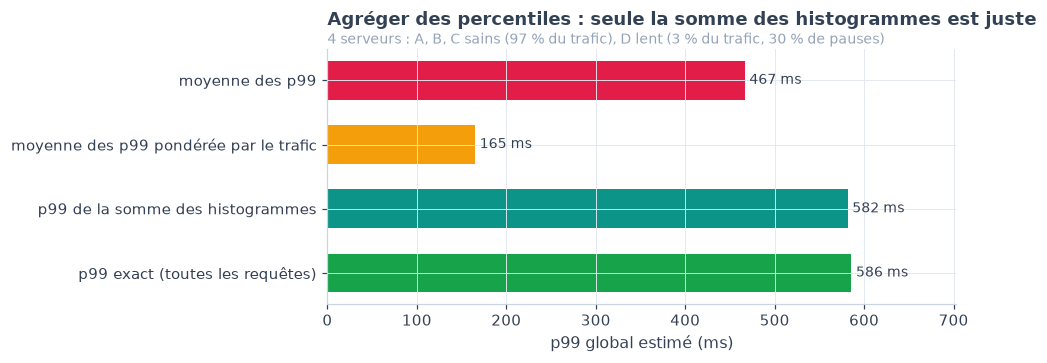

,serveur,requêtes,p99
0,A,60000,122.7
1,B,30000,128.0
2,C,7000,115.9
3,D,3000,1499.7


In [10]:
serveurs = {"A": (60_000, 0.004), "B": (30_000, 0.004), "C": (7_000, 0.004), "D": (3_000, 0.30)}
hists, data, rows = [], [], []
for i, (nom, (nreq, ps)) in enumerate(serveurs.items()):
    v = rq.synthetic_response_times(nreq, seed=10 + i, p_slow=ps)
    h = rq.LogLinearHistogram(5); h.record_many(v)
    hists.append(h); data.append(v)
    rows.append(dict(serveur=nom, requêtes=nreq, p99=rq.percentile(v, 99)))
T = pd.DataFrame(rows)
tout = np.concatenate(data)
verdicts = pd.DataFrame({"p99 (ms)": [T.p99.mean(), np.average(T.p99, weights=T.requêtes),
                                      rq.LogLinearHistogram.merged(hists).percentile(99), rq.percentile(tout, 99)]},
                        index=["moyenne des p99", "moyenne des p99 pondérée par le trafic",
                               "p99 de la somme des histogrammes", "p99 exact (toutes les requêtes)"])
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(verdicts.index[::-1], verdicts["p99 (ms)"].values[::-1], color=[GREEN, TEAL, AMBER, ROSE], height=0.6)
annotate_bars(ax, "{:.0f} ms")
ax.set_xlabel("p99 global estimé (ms)")
ax.set_title("Agréger des percentiles : seule la somme des histogrammes est juste")
subtitle(ax, "4 serveurs : A, B, C sains (97 % du trafic), D lent (3 % du trafic, 30 % de pauses)")
ax.set_xlim(0, verdicts["p99 (ms)"].max() * 1.2)
plt.tight_layout(); plt.show()
T

Les deux moyennes se trompent, et pas dans le même sens : la moyenne simple des p99 donne
environ 470 ms, la moyenne pondérée par le trafic environ 165 ms, alors que le vrai p99
vaut près de 590 ms. Le serveur D ne sert que 3 % du trafic, mais 30 % de ses requêtes
sont ralenties : cela fait 0,9 % de requêtes lentes au total, qui s'ajoutent aux 0,4 % des
autres serveurs. Plus de 1 % des requêtes sont donc lentes, et le p99 global bascule dans
la bosse des requêtes ralenties, ce qu'aucune moyenne de percentiles ne peut voir : un
percentile n'est pas une grandeur additive. La somme des histogrammes donne, à 1,6 % près,
le p99 exact. C'est pourquoi les systèmes de supervision transportent des
histogrammes, et non des percentiles déjà calculés.

> **À retenir.** Pour suivre des percentiles en continu, on stocke des **histogrammes**
> à erreur relative bornée (un par tranche de temps et par machine), qu'on **additionne**
> pour répondre. Moyenner des percentiles n'a pas de sens.

## 5. L'amplification de la latence de queue (section *Describing Performance*)

Les hauts percentiles comptent particulièrement pour les services internes appelés
**plusieurs fois** pour servir une seule requête d'utilisateur. Même en parallèle, la
requête doit attendre **le plus lent** des appels. Si chaque appel est lent avec
probabilité $p$, indépendamment, la requête qui en attend $n$ est lente avec probabilité
$$P(\text{lente}) = 1 - (1 - p)^n.$$
Avec $p = 1\,\%$ et $n = 100$ appels, cela fait 63 % : la queue des services internes
devient le cas *typique* pour l'utilisateur. C'est l'**amplification de la latence de
queue** (tail latency amplification).

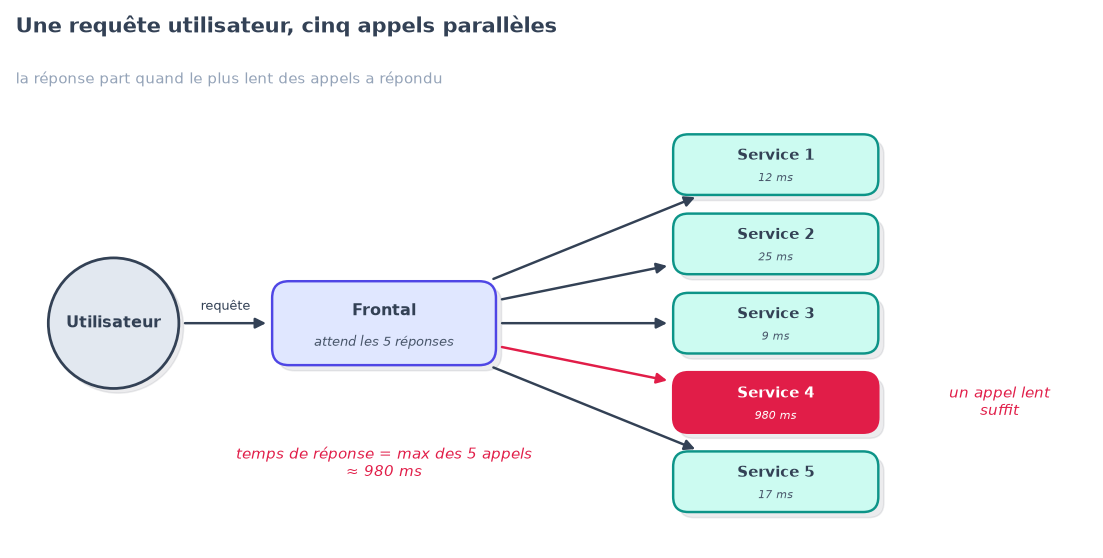

In [11]:
d = Diagram(11.6, 4.8, title="Une requête utilisateur, cinq appels parallèles",
            subtitle="la réponse part quand le plus lent des appels a répondu")
d.box("u", 1.1, 2.4, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("f", 4.0, 2.4, "Frontal", sub="attend les 5 réponses", color=INDIGO, w=2.4)
ys = [4.1, 3.25, 2.4, 1.55, 0.7]
for i, y in enumerate(ys):
    slow = i == 3
    d.box(f"b{i}", 8.2, y, f"Service {i + 1}", sub="980 ms" if slow else f"{[12, 25, 9, 0, 17][i]} ms",
          color=ROSE if slow else TEAL, w=2.2, h=0.65, fontsize=9.5, filled=slow)
    d.arrow("f", f"b{i}", color=ROSE if slow else SLATE)
d.arrow("u", "f", "requête")
d.note(10.6, 1.55, "un appel lent\nsuffit", color=ROSE, fontsize=9.5)
d.note(4.0, 0.9, "temps de réponse = max des 5 appels\n≈ 980 ms", color=ROSE, fontsize=9.5)
d.show()

Vérifions la formule par simulation : on tire les temps de réponse de $n$ appels dans la
distribution du service interne (section 3), et la requête prend le maximum.

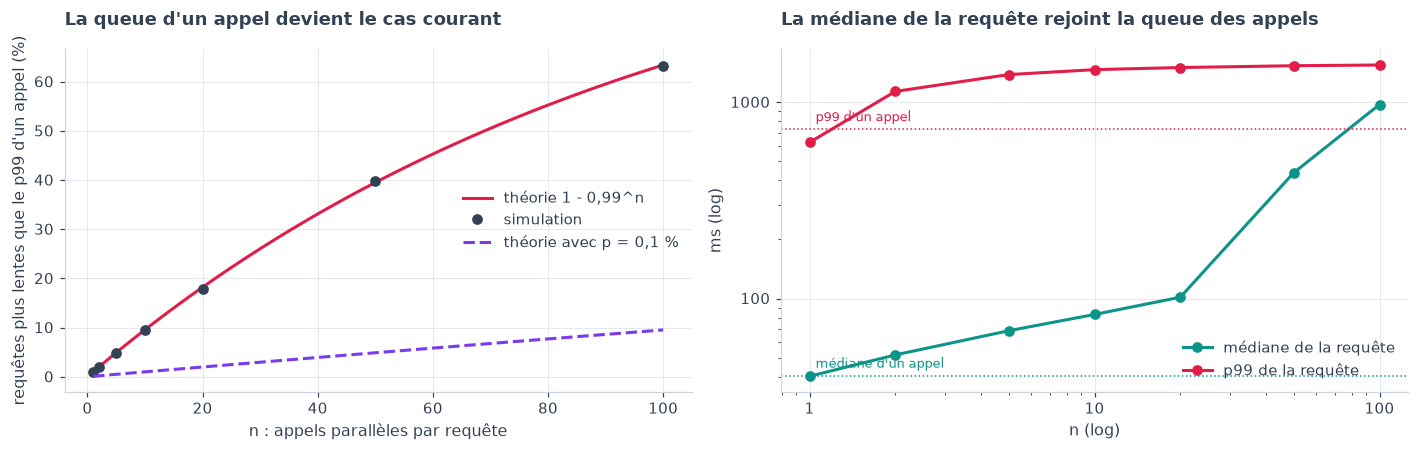

,n,p50,p99,lentes_sim,lentes_theo
0,1,40.2,624.0,0.9,1.0
1,2,51.6,1134.9,2.0,2.0
2,5,68.5,1382.8,4.8,4.9
3,10,82.9,1465.0,9.6,9.6
4,20,101.6,1501.8,17.9,18.2
5,50,437.1,1534.2,39.8,39.5
6,100,973.2,1547.1,63.1,63.4


In [12]:
backend = rq.synthetic_response_times(200_000, seed=0)
p99_b = rq.percentile(backend, 99)
ns = [1, 2, 5, 10, 20, 50, 100]
rows = []
for nn in ns:
    m = rq.fanout_response_times(backend, nn, 20_000, seed=nn)
    rows.append(dict(n=nn, p50=np.percentile(m, 50), p99=np.percentile(m, 99),
                     lentes_sim=(m > p99_b).mean() * 100, lentes_theo=rq.p_any_slow(0.01, nn) * 100))
A = pd.DataFrame(rows)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
nn = np.arange(1, 101)
ax.plot(nn, rq.p_any_slow(0.01, nn) * 100, color=ROSE, label="théorie 1 - 0,99^n")
ax.plot(A.n, A.lentes_sim, "o", color=SLATE, label="simulation")
ax.plot(nn, rq.p_any_slow(0.001, nn) * 100, color=VIOLET, ls="--", label="théorie avec p = 0,1 %")
ax.set_xlabel("n : appels parallèles par requête"); ax.set_ylabel("requêtes plus lentes que le p99 d'un appel (%)")
ax.set_title("La queue d'un appel devient le cas courant")
ax.legend(loc="center right")
ax2.plot(A.n, A.p50, "o-", color=TEAL, label="médiane de la requête")
ax2.plot(A.n, A.p99, "o-", color=ROSE, label="p99 de la requête")
ax2.axhline(np.percentile(backend, 50), color=TEAL, ls=":", lw=1)
ax2.axhline(p99_b, color=ROSE, ls=":", lw=1)
ax2.text(1.05, p99_b * 1.1, "p99 d'un appel", color=ROSE, fontsize=8.5)
ax2.text(1.05, np.percentile(backend, 50) * 1.1, "médiane d'un appel", color=TEAL, fontsize=8.5)
ax2.set_xscale("log"); ax2.set_yscale("log"); rq.plain_log_axis(ax2)
ax2.set_xlabel("n (log)"); ax2.set_ylabel("ms (log)")
ax2.set_title("La médiane de la requête rejoint la queue des appels")
ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()
A

Avec 100 appels, la **médiane** de la requête utilisateur dépasse le p99 d'un appel :
la moitié des utilisateurs subit ce que chaque équipe de service interne considère comme
un cas rare. Inversement, pour garantir un p99 global avec $n$ appels, chaque appel doit
tenir le quantile $0{,}99^{1/n}$ : avec $n = 100$, c'est le **99,99e** percentile
(`rq.per_call_quantile_for(0.99, 100)` ≈ 0,9999). Les grands services
fixent donc des objectifs très exigeants à leurs composants internes, ou recourent à des
techniques qui coupent la queue (exercice 1.4).

> **À retenir.** Une requête qui attend $n$ appels est lente dès que l'un l'est :
> probabilité $1 - (1-p)^n$. Avec beaucoup d'appels, le p99 des composants devient le
> temps de réponse typique : on doit viser des percentiles très élevés en interne.